In [22]:
import pandas as pd
import numpy as np
import sklearn as skl
from narwhals.selectors import categorical
from numpy.ma.core import std
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.model_selection import train_test_split, KFold

In [23]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [24]:
df = pd.read_csv(url)

In [25]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [26]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [27]:
features = list(set(df.dtypes.index.tolist()) - set(['converted']))
categorical = df.dtypes[df.dtypes == 'str'].index.tolist()
numeric = list((set(features) - set(categorical)))

In [28]:
df[categorical] = df[categorical].fillna('NA')

In [29]:
df[numeric] = df[numeric].fillna(0.0)

In [30]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [31]:
#Question 1

In [32]:
from sklearn.metrics import roc_auc_score
for col in numeric:
    score = roc_auc_score(df_train.converted, df_train[col])
    if score < 0.5:
        score = roc_auc_score(df_train.converted, -df_train[col])
    print(f'{col} {score}')
    print()

lead_score 0.7882254810906102

interaction_count 0.7649203047563227

number_of_courses_viewed 0.7229894623989618

annual_income 0.6081977776250831



In [33]:
from sklearn.linear_model import LinearRegression, LogisticRegression

dv = DictVectorizer(sparse=False)

In [34]:
dict_train = df_train[features].to_dict(orient='records')
dict_test = df_test[features].to_dict(orient='records')
dict_val = df_val[features].to_dict(orient='records')
dict_full_train = df_full_train[features].to_dict(orient='records')

X_train = dv.fit_transform(dict_train)
y_train = df_train.converted.values

In [35]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

X_val = dv.transform(dict_val)
y_pred = model.predict_proba(X_val)[:,1]

In [36]:
round(roc_auc_score(df_val.converted, y_pred),3)

0.732

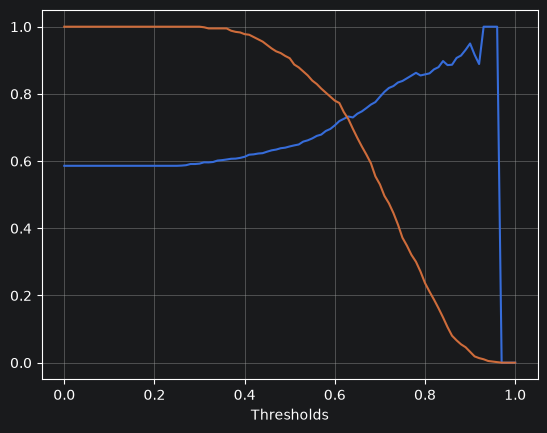

abs min = 0.63 0.007502647993409384
max f1 = 0.41000000000000003 0.7576158940397352


In [37]:
#Q3
import matplotlib.pyplot as plt

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

abs_min = 1
abs_min_r = 0

max_f1 = 0
max_f1_r = 0

for r in thresholds:
    thresholded = y_pred >= r

    precision = precision_score(df_val.converted, thresholded, zero_division=0)
    recall = recall_score(df_val.converted, thresholded, zero_division=0)

    if recall !=0 and precision !=0 and abs_min > np.abs(precision - recall):
        abs_min = np.abs(precision - recall)
        abs_min_r = r
    precisions.append(precision)
    recalls.append(recall)

    if not (precision ==0 and recall ==0):
        F1 = 2 * precision * recall / (precision + recall)

        if max_f1 < F1:
            max_f1 = F1
            max_f1_r = r

plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
plt.xlabel('Thresholds')
plt.grid()
plt.show()

print(f'abs min = {abs_min_r} {abs_min}')
print(f'max f1 = {max_f1_r} {max_f1}')


In [56]:
def get_roc_aucs(roc_aucs, c):
    for train_idx, val_idx in kf.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dict_train = df_train[features].to_dict(orient='records')
        dict_val = df_val[features].to_dict(orient='records')

        X_train = dv.fit_transform(dict_train)
        X_val = dv.transform(dict_val)

        model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:,1]

        roc_auc = roc_auc_score(y_val, y_pred)
        roc_aucs.append(roc_auc)

In [58]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)
arr = []
get_roc_aucs(arr, 1.0)

#Q5
print(f'std_deviation = {round(np.std(arr),3)}')

#Q6
Cs = [0.000001, 0.001, 1]
for C in Cs:
    arr = []
    get_roc_aucs(arr, C)
    print(f'C={C}: mean={np.mean(arr):.3f}, std={np.std(arr):.3f}')





std_deviation = 0.007
C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007
